# Fit an IRD spectrum with the Coelho grid

This tutorial uses `jaxstar.specfit` to fit two orders of an IRD spectrum with
Coelho synthetic spectra. The model combines stellar atmosphere parameters,
rotational and macroturbulent broadening, instrumental resolution, a
multiplicative continuum, and a Gaussian process (GP) for correlated residuals.

The workflow is to prepare the observations and model grid, estimate radial
velocity with a cross-correlation function (CCF), obtain an initial point
estimate with SVI, mask outliers and refit, and sample the posterior with NUTS.
The final sections inspect the fit and demonstrate saving and loading results.

## Setup

Use a Jupyter-compatible notebook frontend and install the source checkout into
the Python environment selected by its kernel. From the repository root, run:

```bash
python -m pip install -e . seaborn ipykernel
```

Seaborn supplies the plotting style used below. The package dependencies include
Pandas, ArviZ, Corner, and the `h5netcdf`/`h5py` backend used to save posterior
samples. The example reads `sample_data_ird.csv` and the Coelho `*_normed.npz`
grids from `examples/specfit/coelho/`.

Start a fresh kernel with the repository root or `examples/specfit` as the
working directory, then run the cells in order. The setup selects CPU execution,
enables 64-bit JAX calculations, and requests two host devices for the two NUTS
chains before the JAX backend is initialized.

Set `result_dir` before plotting. All plots are displayed in the notebook.
Observation, CCF, outlier, posterior-spectrum,
and MCMC diagnostic figures are saved as PDFs when drawn; an existing PDF
with the same name is replaced. The fit result bundle is saved separately
in Section 11.

In [1]:
import numpyro 
num_chains = 2
numpyro.set_host_device_count(num_chains)

from pathlib import Path
import sys

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src/jaxstar/specfit/model.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the jaxstar repository.")
sys.path.insert(0, str(ROOT / "src"))

import jax
jax.config.update("jax_platform_name", "cpu")
jax.config.update("jax_enable_x64", True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from numpyro.infer import init_to_value
from jaxstar.specfit import (
    Observation, SpecFit, select_grid_paths,
)

from jaxstar.specfit.numpyro_model import make_model_single

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 100, "figure.facecolor": "white",
})
print("Backend:", jax.default_backend(), "JAX:", jax.__version__)

Backend: cpu JAX: 0.11.2


In [2]:
# Output directory for fit results and figures
result_dir = ROOT / "examples/specfit/results"
result_dir.mkdir(parents=True, exist_ok=True)


In [3]:
import seaborn as sns
sns.set(style='ticks', font_scale=1.3, font='times')
from matplotlib import rc
rc('text', usetex=False)

## 1. Load the observed spectrum

The CSV contains concatenated orders with 2,048 pixels per order. Reshape each
column and select the zero-based order indices `[8, 9]`. These indices also
become the region labels used in diagnostics and output filenames.

Convert `lam` from nm to Å, and read `normed_flux`, `flux_error`, and `all_mask`.
In an `Observation`, `mask=True` excludes a pixel. The loader adds nonfinite
flux/error values and nonpositive errors to this fixed data mask. Wavelengths
must be finite, positive, and strictly increasing within every order, including
masked pixels.

Inspect the usable-pixel counts and the plot before fitting. The plot is saved
as `observation.pdf` in `result_dir`.

In [4]:
gridpath = ROOT / "examples/specfit/coelho"
datapath = gridpath / "sample_data_ird.csv"
orders = [8, 9]


def load_ird_spectrum(datapath, orders):
    data = pd.read_csv(datapath)

    def rows(name):
        return data[name].to_numpy().reshape(-1, 2048)[orders].copy()

    wavelength = rows("lam") * 10.0  # nm -> Angstrom
    flux = rows("normed_flux")
    error = rows("flux_error")
    mask = rows("all_mask").astype(bool)
    mask |= ~np.isfinite(flux) | ~np.isfinite(error) | (error <= 0)
    return wavelength, flux, error, mask


wav_obs, flux_obs, error_obs, mask_obs = load_ird_spectrum(datapath, orders)
obs = Observation(
    wav_obs, flux_obs, error_obs, mask=mask_obs, region=orders,
)
print("Observation shape:", obs.shape)
print("Usable pixels per order:", np.sum(obs.valid, axis=1))

Observation shape: (2, 2048)
Usable pixels per order: [1546 1754]


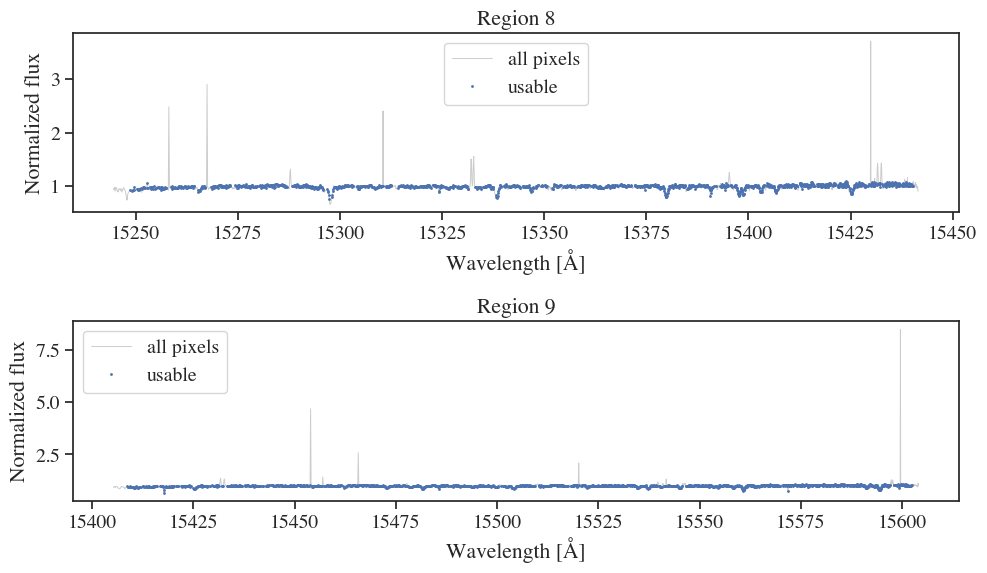

In [5]:
fig, axes = plt.subplots(obs.n_regions, 1, figsize=(10, 3 * obs.n_regions), squeeze=False)
for i, region in enumerate(obs.region):
    ax = axes[i, 0]
    usable = ~mask_obs[i]
    ax.plot(wav_obs[i], flux_obs[i], color="0.8", lw=0.7, label="all pixels")
    ax.plot(wav_obs[i, usable], flux_obs[i, usable], ".", ms=2, label="usable")
    ax.set(title=f"Region {region}", xlabel="Wavelength [Å]", ylabel="Normalized flux")
    ax.legend()
fig.tight_layout()

## 2. Inspect the grid selection

`select_grid_paths` finds one `*_normed.npz` file for each observed region. It
checks the wavelength range stored in each file's `wavgrid` and requires at
least `wav_margin=3.0` Å of coverage beyond both observed endpoints, including
masked pixels. A missing or ambiguous match raises an error identifying the
region and candidate files.

The table shows which grid will be used for each order. This inspection is
optional: `SpecFit.from_grid` performs the same selection in the next section.
The NPZ files do not specify an air/vacuum wavelength convention, and no
conversion is applied. When substituting other data, use matching wavelength
units and conventions for the observations and grids.

In [6]:
grid_paths = select_grid_paths(
    gridpath, obs.wavelength, regions=obs.region,
    wav_margin=3.0, pattern="*_normed.npz",
)
display(pd.DataFrame({"region": obs.region, "grid": [p.name for p in grid_paths]}))

,region,grid
0,8,15239-15449_normed.npz
1,9,15399-15611_normed.npz


## 3. Build the spectral model and fitter

`SpecFit.from_grid` loads the selected grids, resamples them onto grids evenly
spaced in log wavelength, and combines a `SpecModel` with the `Observation`.
`flux_kind="normalized"` declares that the stored grid spectra are normalized.

Here, `pixels=5000` sets the number of model wavelength samples in each region.
For these grids, the resulting velocity spacing is about 0.82 km/s. This is the
model sampling, separate from the observed pixel count and instrumental
resolving power. `vmax=50.0` km/s sets the half-width of the broadening kernel.

The following table reports the available atmosphere-parameter bounds; the
printed shapes and velocity steps describe the prepared model. If a model has
already been constructed, it can also be paired with data using
`SpecFit(obs, specmodel)`.

In [7]:
sf = SpecFit.from_grid(
    gridpath, obs, library="coelho", pattern="*_normed.npz",
    wav_margin=3.0, pixels=5000, vmax=50.0, flux_kind="normalized",
)

In [8]:
specmodel = sf.specmodel
spectra = specmodel.spectra

axis_bounds = {
    name: (float(spectra.grid.axis(name)[0]), float(spectra.grid.axis(name)[-1]))
    for name in spectra.grid.axis_names
}
display(pd.DataFrame(axis_bounds, index=["lower", "upper"]).T)
print("Model wavelength shape:", spectra.wavelength.shape)
print("Model velocity steps [km/s]:",
      np.asarray(specmodel.velocity_grid[:, 1] - specmodel.velocity_grid[:, 0]))

,lower,upper
teff,3500.0,7000.0
logg,1.0,5.0
feh,-1.0,0.5
alpha,0.0,0.4


Model wavelength shape: (2, 5000)
Model velocity steps [km/s]: [0.82075586 0.81989219]


## 4. Estimate radial velocity with the CCF

Cross-correlate the usable observed pixels against a template with
`teff=6000` K, `logg=4.0`, `feh=0.0`, and `alpha=0.0`. `v_limit=100.0` restricts
the peak search to velocities within ±100 km/s, while `ccfvmax=100.0` sets the
half-width of the combined CCF window around the estimated radial velocity.

`check_ccf` returns the median of the per-order radial velocities and the full
width at half maximum of the combined CCF, both in km/s. It also stores these
results in `sf.ccf` for constructing the priors below. The CCF width helps set a
rotation prior; it is not a direct measurement of `vsini`.

Inspect the peak and width in the plot, which is saved as `ccf.pdf`.

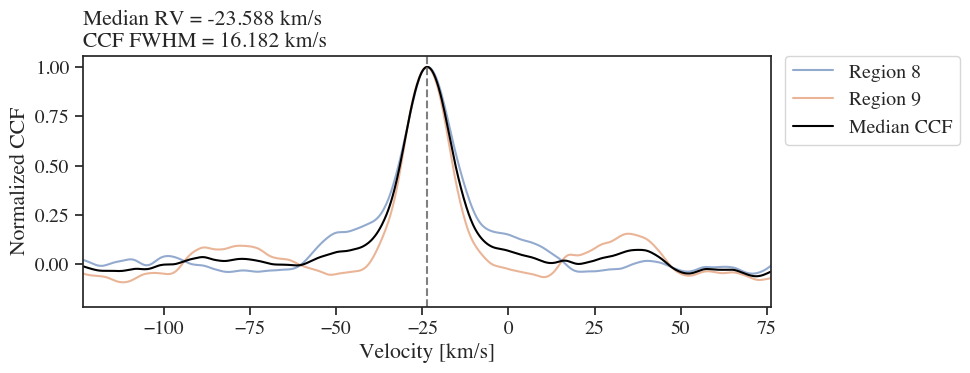

In [9]:
template_atmosphere = {"teff": 6000.0, "logg": 4.0, "feh": 0.0, "alpha": 0.0}

ccf_rv, ccf_width = sf.check_ccf(
    template_atmosphere, v_limit=100.0, ccfvmax=100.0, plot=True,
    save_path=result_dir / "ccf.pdf",
)

## 5. Configure the model and inspect its priors

`make_model_single(sf, ...)` prepares a callable model from the grid, CCF, and
chosen settings. Pass this same `model` to inference and prediction methods.
The atmosphere parameters (`teff`, `logg`, `feh`, and `alpha`) and broadening
parameters are shared by the two orders; each order has its own radial velocity.

The configuration below uses these settings:

- `RESOLVING_POWER=70_000.0` fixes the instrumental resolving power to 70,000
  in both orders. The array allows a different value to be supplied per order.
- `use_physical_logg_max=True` restricts the temperature prior to the intersection
  of the grid bounds and 4,500–7,000 K. The gravity prior runs from the grid's
  lower bound to `physical_logg_max(teff)`, with its support checked against the
  grid. Other atmosphere priors are uniform over their grid ranges; singleton
  axes are fixed.
- Each radial velocity has a uniform prior centered on the median CCF velocity.
  Its half-width is 5 km/s when the CCF width is below 20 km/s, otherwise half
  the CCF width. `vsini` is uniform from zero to the smaller of the CCF width
  and 90% of the broadening kernel's velocity support.
- `USE_EMPIRICAL_VMACRO=False` uses the factory's default uniform prior of
  1–15 km/s for `vmacro`. Setting it to `True` instead uses a temperature-dependent
  macroturbulence prior. The limb-darkening parameters `q1` and `q2` each have
  a uniform prior on [0, 1].
- The default `degree=4` uses a fourth-degree Chebyshev continuum in each order.
  Its coefficients are integrated out analytically under Gaussian priors.
  The constant coefficient has mean 1 and scale `0.1`; the remaining
  coefficients have mean 0 and scale `0.05`.
- `USE_GP=True` enables independent Matérn-3/2 residual GPs for the two orders,
  with shared hyperparameters. `GP_SOLVER="auto"` selects exact GP inference
  with `quasisep` on CPU or `direct` on GPU. Jitter adds independent noise
  in quadrature to the observed uncertainties.

Set `GP_SOLVER="vecchia1"` to try the experimental fast GP approximation.
See the [Vecchia guide](../../docs/specfit.md#experimental-nearest-neighbor-likelihood)
for its limitations and how to compare it with exact GP inference.

The noise priors are log-uniform over the following positive ranges:

| Parameter | Range | Units |
| --- | --- | --- |
| `jitter` | `1e-3` to `0.05` | Normalized flux |
| `gp_amplitude` | `1e-3` to `0.05` | Normalized flux |
| `gp_scale` | 5 km/s equivalent to region span / 5 | Å |

Jitter and amplitude bounds are independent of observational errors and masks.
The shared scale interval uses the largest lower and smallest upper bound
across orders, using their full wavelength spans and midpoints. These bounds
are fixed at model creation and do not change with outlier masking.

`model.check_prior()` lists the actual priors, fixed values, and derived
quantities without computing the likelihood. Conditional priors show their
dependencies; `model.check_prior(condition={"teff": 5800.0})` also evaluates
the gravity upper bound at that temperature.

To customize the model, pass options such as
`atmosphere_bounds={"teff": (5000.0, 6500.0)}` or
`fixed={"logg": 4.4, "vmacro": 0.0}` when constructing it.
`model.settings` is read-only, so call `make_model_single` again to change
settings. For a different target or wavelength range, inspect `sf.rv_bounds`
and compare it with `model.settings["rv_bounds"]`: the velocity prior is not
automatically clipped to the model's wavelength coverage.

In [10]:
USE_EMPIRICAL_VMACRO = False
USE_GP = True
GP_SOLVER = "auto"  # Or "vecchia1" for the experimental approximation.
RESOLVING_POWER = 70_000.0

resolving_power = np.full(obs.n_regions, RESOLVING_POWER)
model = make_model_single(
    sf, resolving_power=resolving_power, use_gp=USE_GP,
    gp_solver=GP_SOLVER, use_physical_logg_max=True,
    use_empirical_vmic=False, use_empirical_vmacro=USE_EMPIRICAL_VMACRO,
)


In [11]:
model.check_prior()

,prior
parameter,
teff,"Uniform(4500, 7000)"
logg | teff,"Uniform(logg_min, physical_logg_max(teff))"
feh,"Uniform(-1, 0.5)"
alpha,"Uniform(0, 0.4)"
vsini,"Uniform(0, 16.1816)"
vmacro,"Uniform(1, 15)"
q1,"Uniform(0, 1)"
q2,"Uniform(0, 1)"
rv,"Uniform([-28.5881, -28.5881], [-18.5881, -18.5..."


## 6. Obtain an initial point estimate with SVI

Run 2,000 SVI optimization steps with `step_size=0.1` and a fixed random seed.
With no `p_initial`, initialization draws from the model's priors. The returned
`p_fit` is a point estimate keyed by NumPyro site names, in physical units; the
posterior samples will be obtained with NUTS in Section 8.

`plot_models(point=p_fit, model=model)` reconstructs the spectrum, conditional
continuum, and GP mean (except with `vecchia1`, which reconstructs only the
continuum-corrected spectrum). The initial-fit plots are displayed for inspection.

Inspect `p_fit` and the residual diagnostics. By default, the diagnostic table
uses residuals after subtracting both the continuum-corrected spectrum and GP
mean when available. Its standardized residuals use the observed uncertainty
and jitter in quadrature; they are not whitened by the GP covariance.

In [12]:
p_fit = sf.run_svi(
    rng_key=jax.random.PRNGKey(0), model=model,
    step_size=1e-1, num_steps=2000,
)

100%|██████████| 2000/2000 [00:54<00:00, 36.37it/s, init loss: -6266.2361, avg. loss [1901-2000]: -8325.6952]


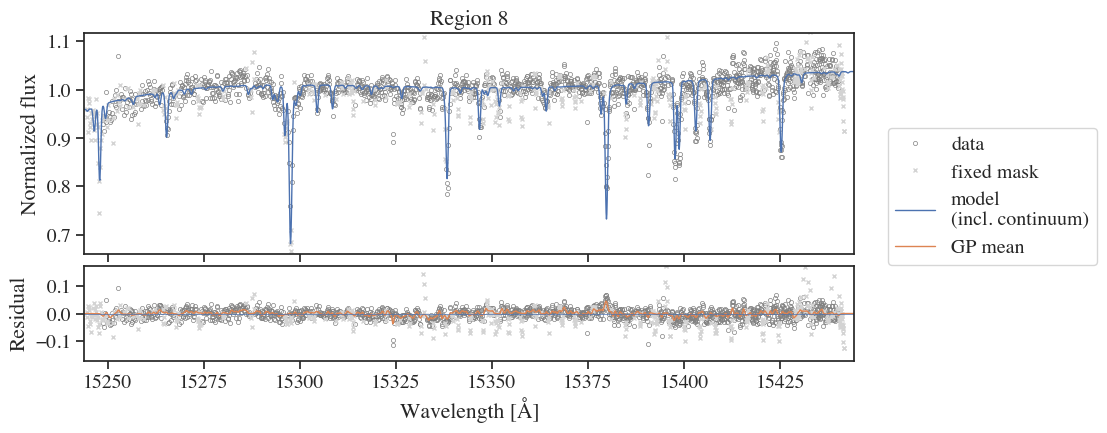

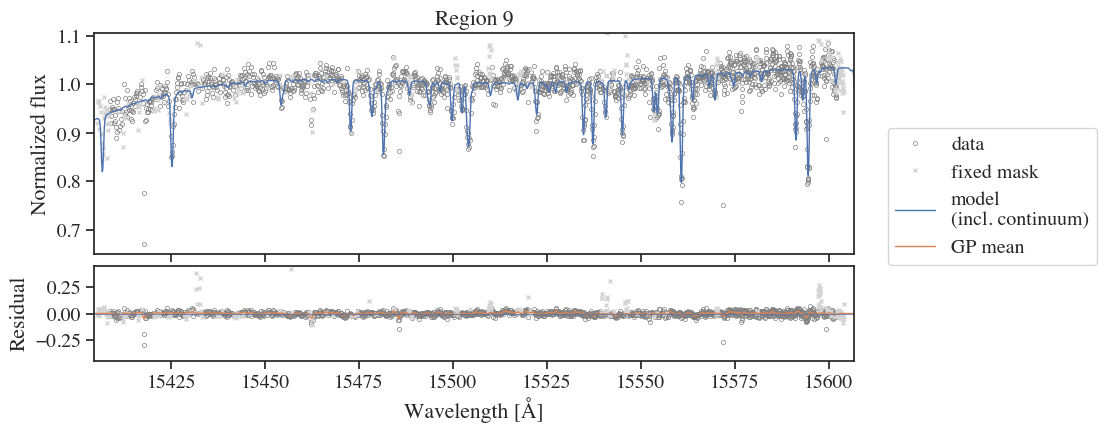

In [13]:
_ = sf.plot_models(
    point=p_fit, model=model, show_gp=USE_GP,
)

In [14]:
p_fit

{'teff': Array(6203.38148865, dtype=float64),
 'logg': Array(4.05692503, dtype=float64),
 'feh': Array(0.15062883, dtype=float64),
 'alpha': Array(0.01772795, dtype=float64),
 'vsini': Array(7.58441943, dtype=float64),
 'vmacro': Array(4.66532299, dtype=float64),
 'q1': Array(0.46998553, dtype=float64),
 'q2': Array(0.46772223, dtype=float64),
 'rv': Array([-23.18910215, -23.65510776], dtype=float64),
 'resolving_power': Array([70000., 70000.], dtype=float64),
 'sigma_constant': Array(0.1, dtype=float64, weak_type=True),
 'sigma_continuum': Array(0.05, dtype=float64, weak_type=True),
 'jitter': Array(0.00131679, dtype=float64),
 'gp_amplitude': Array(0.01132301, dtype=float64),
 'gp_scale': Array(0.41662224, dtype=float64),
 'u1': Array(0.64129855, dtype=float64),
 'u2': Array(0.04425636, dtype=float64)}

In [15]:
display(pd.DataFrame(sf.residual_diagnostics(point=p_fit, model=model)))

,region,n_usable,rms,mad_scale,standardized_rms,n_gt_3sigma,n_gt_5sigma,n_adjacent_pairs,lag1_correlation
0,8,1546,0.015288,0.014578,0.809217,8,1,1446,-0.056443
1,9,1754,0.017652,0.013361,0.871320,7,5,1682,0.073397


## 7. Mask outliers and refit

`mask_outliers` predicts once using the initial `p_fit`, then updates the
adjustable fit mask while preserving the fixed data mask. Gaussian-mixture
masking uses residuals relative to `model_flux` (the physical spectrum
multiplied by the conditional continuum), excluding the GP mean. The normal
component has variance `V = gp_amplitude**2 + uncertainty**2 + jitter**2`;
a broader component represents local data-model mismatch.

Pixels with mismatch probability greater than `p_outlier=0.5` are flagged.
`mask_velocity=10.` extends the mask by ±10 km/s around each flagged pixel
within its region. The mixture is used only for outlier selection; the fitting
likelihood and continuum marginalization are unchanged.

Each diagnostic plot shows the data and baseline at the top, residuals and
the normal residual scale `sqrt(V)` in the middle, and mismatch probabilities
with their threshold at the bottom. The histogram shows residuals divided by
`sqrt(V)` with a standard-normal reference. Highlighted points include the
mask extension. The figures are saved as `outliers_region8.pdf` and
`outliers_region9.pdf` at the time the mask is updated.

Review these plots and `mask_summary()`, then refit for 1,000 steps with
`step_size=0.1`, initializing from the first `p_fit`. This new SVI call uses the
updated mask. Keep that mask fixed for NUTS and posterior reconstruction.
Calling `mask_outliers` again repeats the selection using the current fit; it
is not needed to save the figures again.

,region,fixed_mask,fit_mask,usable
0,8,502,21,1525
1,9,294,47,1707


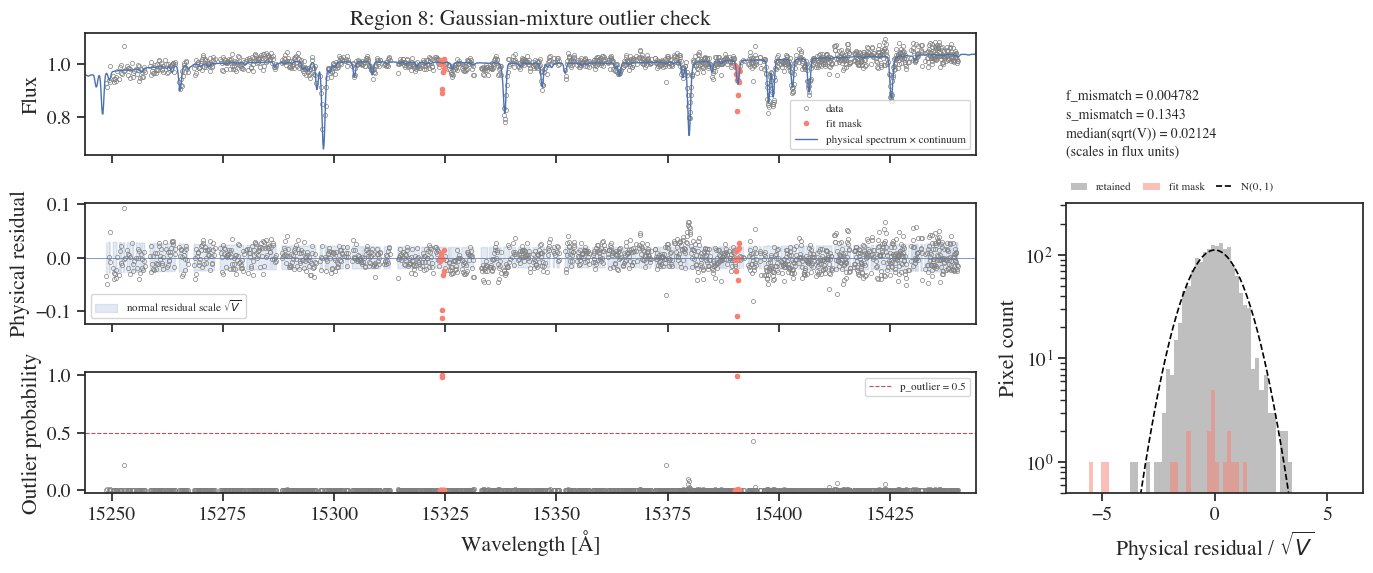

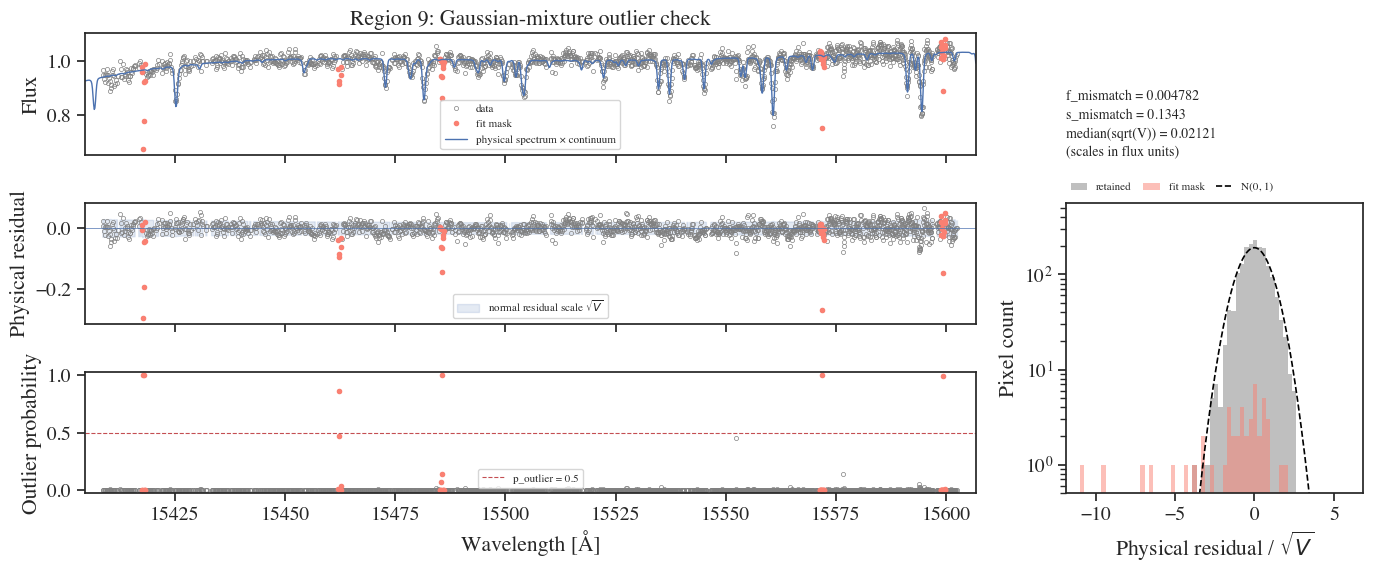

In [16]:
sf.mask_outliers(
    point=p_fit, model=model,
    method="gaussian_mixture", p_outlier=0.5, mask_velocity=10.,
    plot=True, save_path=result_dir / "outliers.pdf",
)
display(pd.DataFrame(sf.mask_summary()))
plt.show()

In [17]:
p_fit = sf.run_svi(
    rng_key=jax.random.PRNGKey(1), model=model,
    step_size=1e-1, num_steps=1000, p_initial=p_fit,
)

100%|██████████| 1000/1000 [00:26<00:00, 37.97it/s, init loss: -8375.6389, avg. loss [951-1000]: -8383.9014]


## 8. Sample the posterior with NUTS

Initialize NUTS from the refitted `p_fit` using `init_to_value`. The run uses
the `num_chains=2` set during setup, with 500 warmup iterations and 1,000
retained samples per chain. The sampler uses `target_accept_prob=0.90`,
`dense_mass=True`, and `max_tree_depth=6`. The model settings and fit mask stay
fixed during sampling.

Inspect the printed effective sample sizes, `r_hat`, and divergence count,
together with the trace plots in Section 10. These run lengths are tutorial
settings; assess convergence before interpreting the posterior and increase
the sampling effort if needed.

`mcmc.get_samples()` combines chain and draw axes for spectrum prediction.
The `mcmc` object retains the separate chains for diagnostics and saving.

In [18]:
mcmc = sf.run_nuts(
    rng_key=jax.random.PRNGKey(2), model=model,
    num_warmup=500, num_samples=1000, num_chains=num_chains,
    nuts_kwargs={
        "init_strategy": init_to_value(values=p_fit),
        "target_accept_prob": 0.90, "dense_mass": True, "max_tree_depth": 6,
    },
)

  0%|          | 0/1500 [00:00<?, ?it/s]

  0%|          | 0/1500 [00:00<?, ?it/s]

In [19]:
mcmc.print_summary(exclude_deterministic=True)
samples = mcmc.get_samples()


                    mean       std    median      5.0%     95.0%     n_eff     r_hat
         alpha      0.01      0.01      0.01      0.00      0.03   2196.82      1.00
           feh      0.17      0.04      0.17      0.11      0.24   1292.14      1.00
  gp_amplitude      0.01      0.00      0.01      0.01      0.01   1520.64      1.00
      gp_scale      0.51      0.07      0.51      0.40      0.62   1346.10      1.00
        jitter      0.00      0.00      0.00      0.00      0.00   2411.53      1.00
          logg      4.24      0.20      4.27      3.95      4.57    712.83      1.00
            q1      0.50      0.29      0.49      0.03      0.93   1434.18      1.00
            q2      0.50      0.29      0.49      0.10      0.99   1957.15      1.00
         rv[0]    -23.12      0.16    -23.11    -23.40    -22.86   1609.10      1.00
         rv[1]    -23.64      0.17    -23.65    -23.91    -23.37   2392.24      1.00
          teff   6253.92    112.55   6266.00   6069.37   6432.81

## 9. Plot the posterior mean spectrum

With `samples=samples` and `max_draws=50`, `plot_models` selects up to 50 evenly
spaced posterior draws, reconstructs each spectrum and its conditional
continuum/GP, and averages the resulting curves.

The upper panel shows the observations and the mean continuum-corrected model.
The lower panel shows residuals relative to that model; `show_gp=USE_GP` overlays
the mean GP contribution for exact GP solvers; `vecchia1` omits this overlay.
These are averages of conditional mean predictions, without simulated
measurement noise.

The plots are saved as `model_region8.pdf` and `model_region9.pdf`.
To retrieve the prediction arrays, use
`sf.predict(samples=samples, model=model, max_draws=50)`.

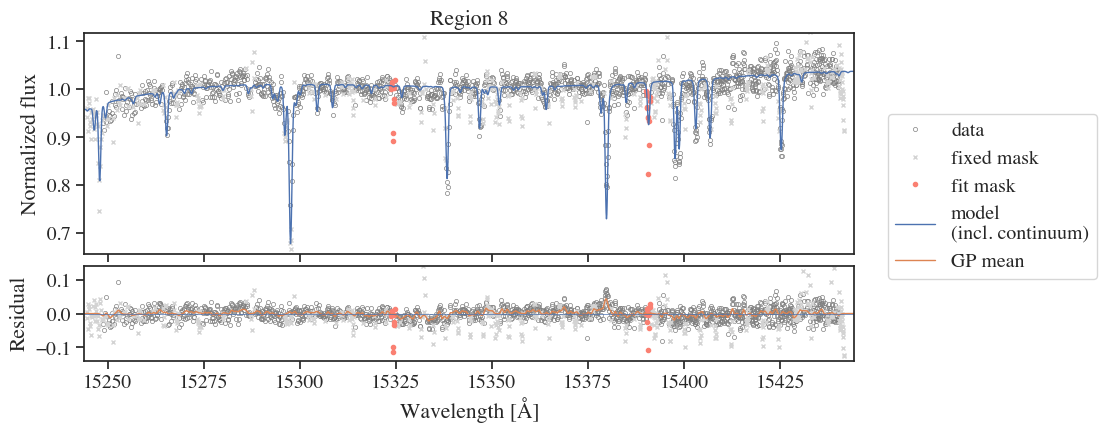

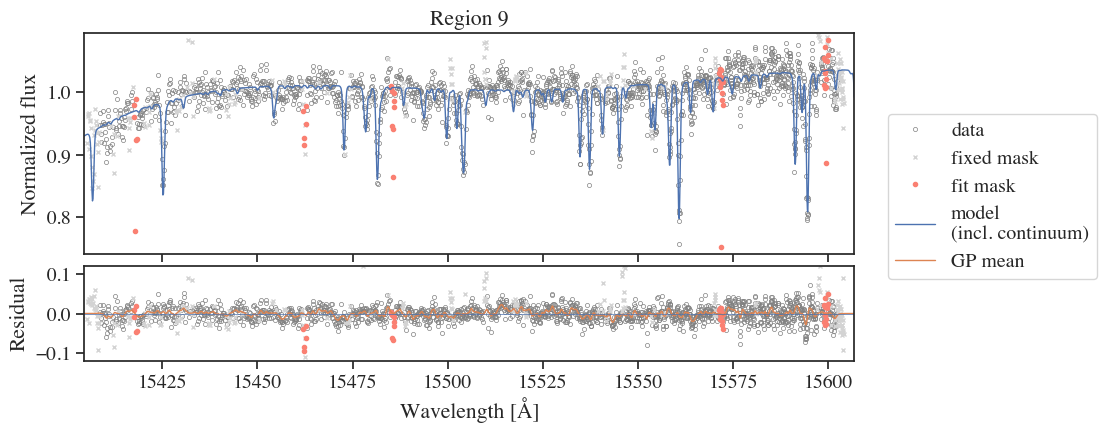

In [20]:
model_figures = sf.plot_models(
    samples=samples, model=model, show_gp=USE_GP, max_draws=50,
    save_path=result_dir / "model.pdf",
)
plt.show()

## 10. Inspect trace and corner plots

`plot_mcmc_diagnostics` displays all sampled variables in the trace plot by
default, excluding fixed and derived quantities. Radial velocities are shown
separately for each region, and chains remain separate. Use `trace_vars` to
select a subset. `corner_vars` independently selects the variables shown in
the corner plot.

Here, `log_vars` displays jitter and the GP hyperparameters on a natural-log
scale in both figures. The `labels` mapping names these plotted quantities
`lnsigma`, `lna`, and `lnc`, and labels `vmacro` as `zeta`. Variable selection
still uses the original site names. These display transformations preserve the
stored samples, chain/draw structure, region labels, and divergence information.

Use the trace plots to assess mixing and the corner plot to inspect parameter
correlations. The method returns a dictionary of Figure objects named `trace`
and `corner`; the following loop saves them immediately as `trace.pdf` and
`corner.pdf`. Plotting these diagnostics does not reevaluate the spectral model.

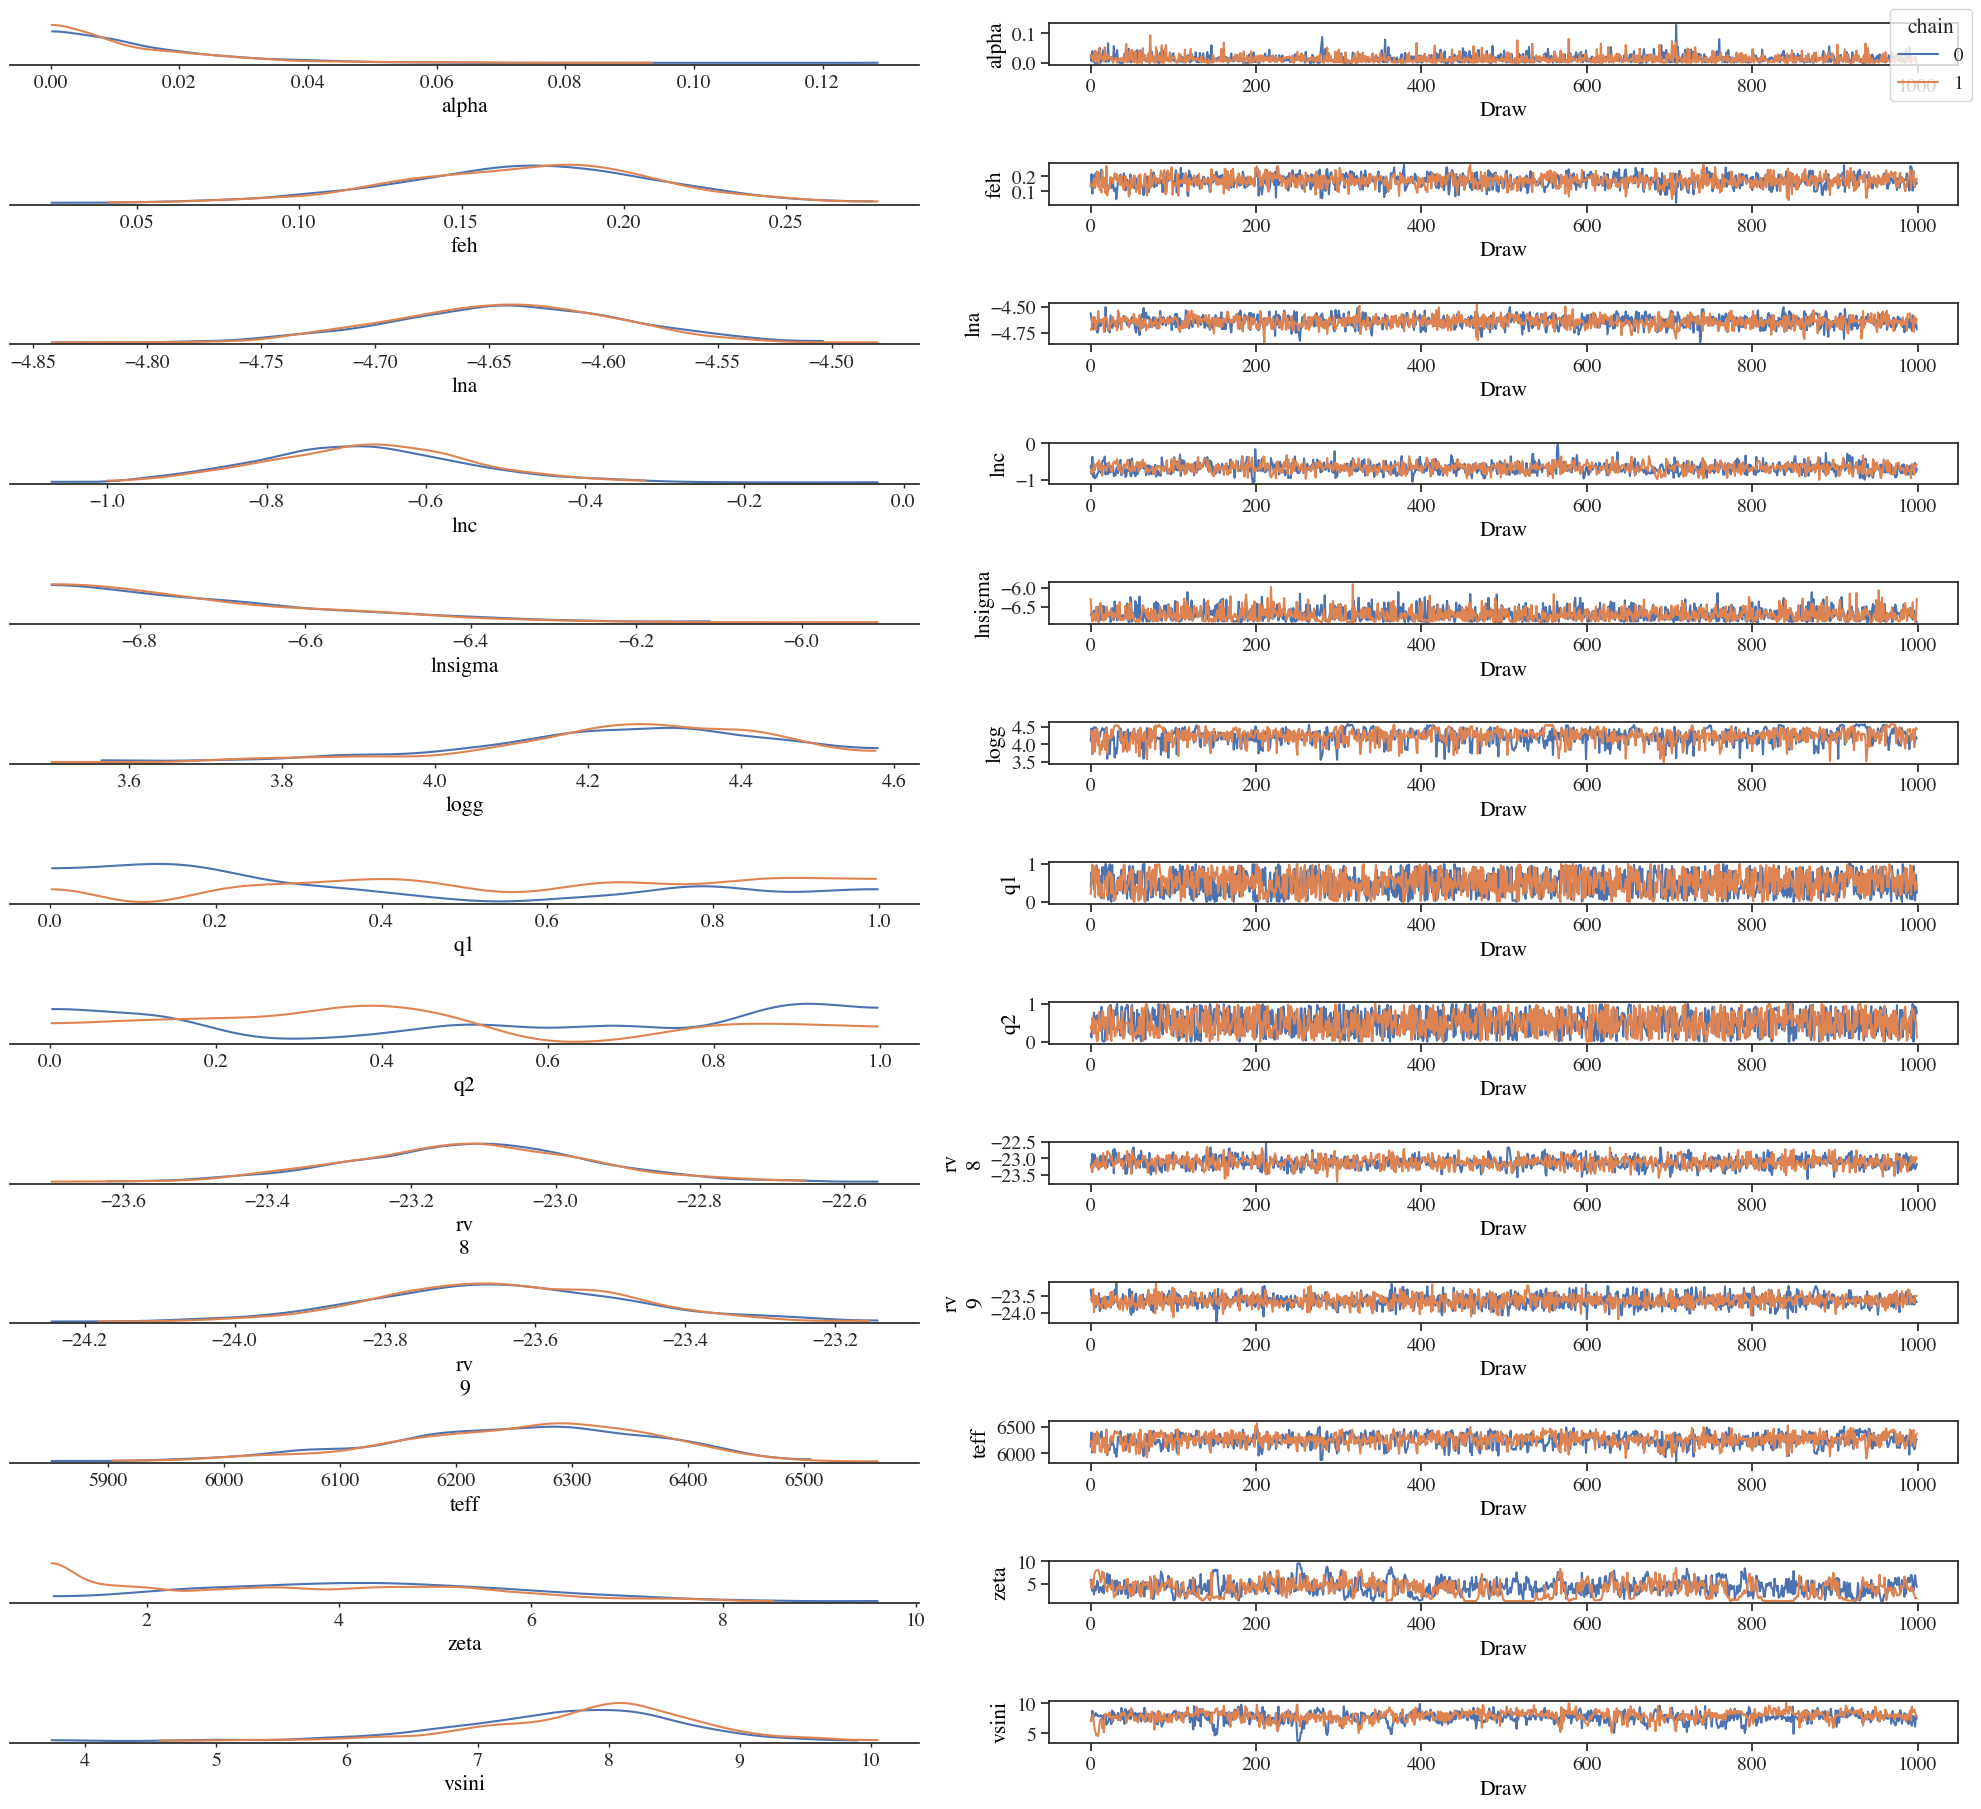

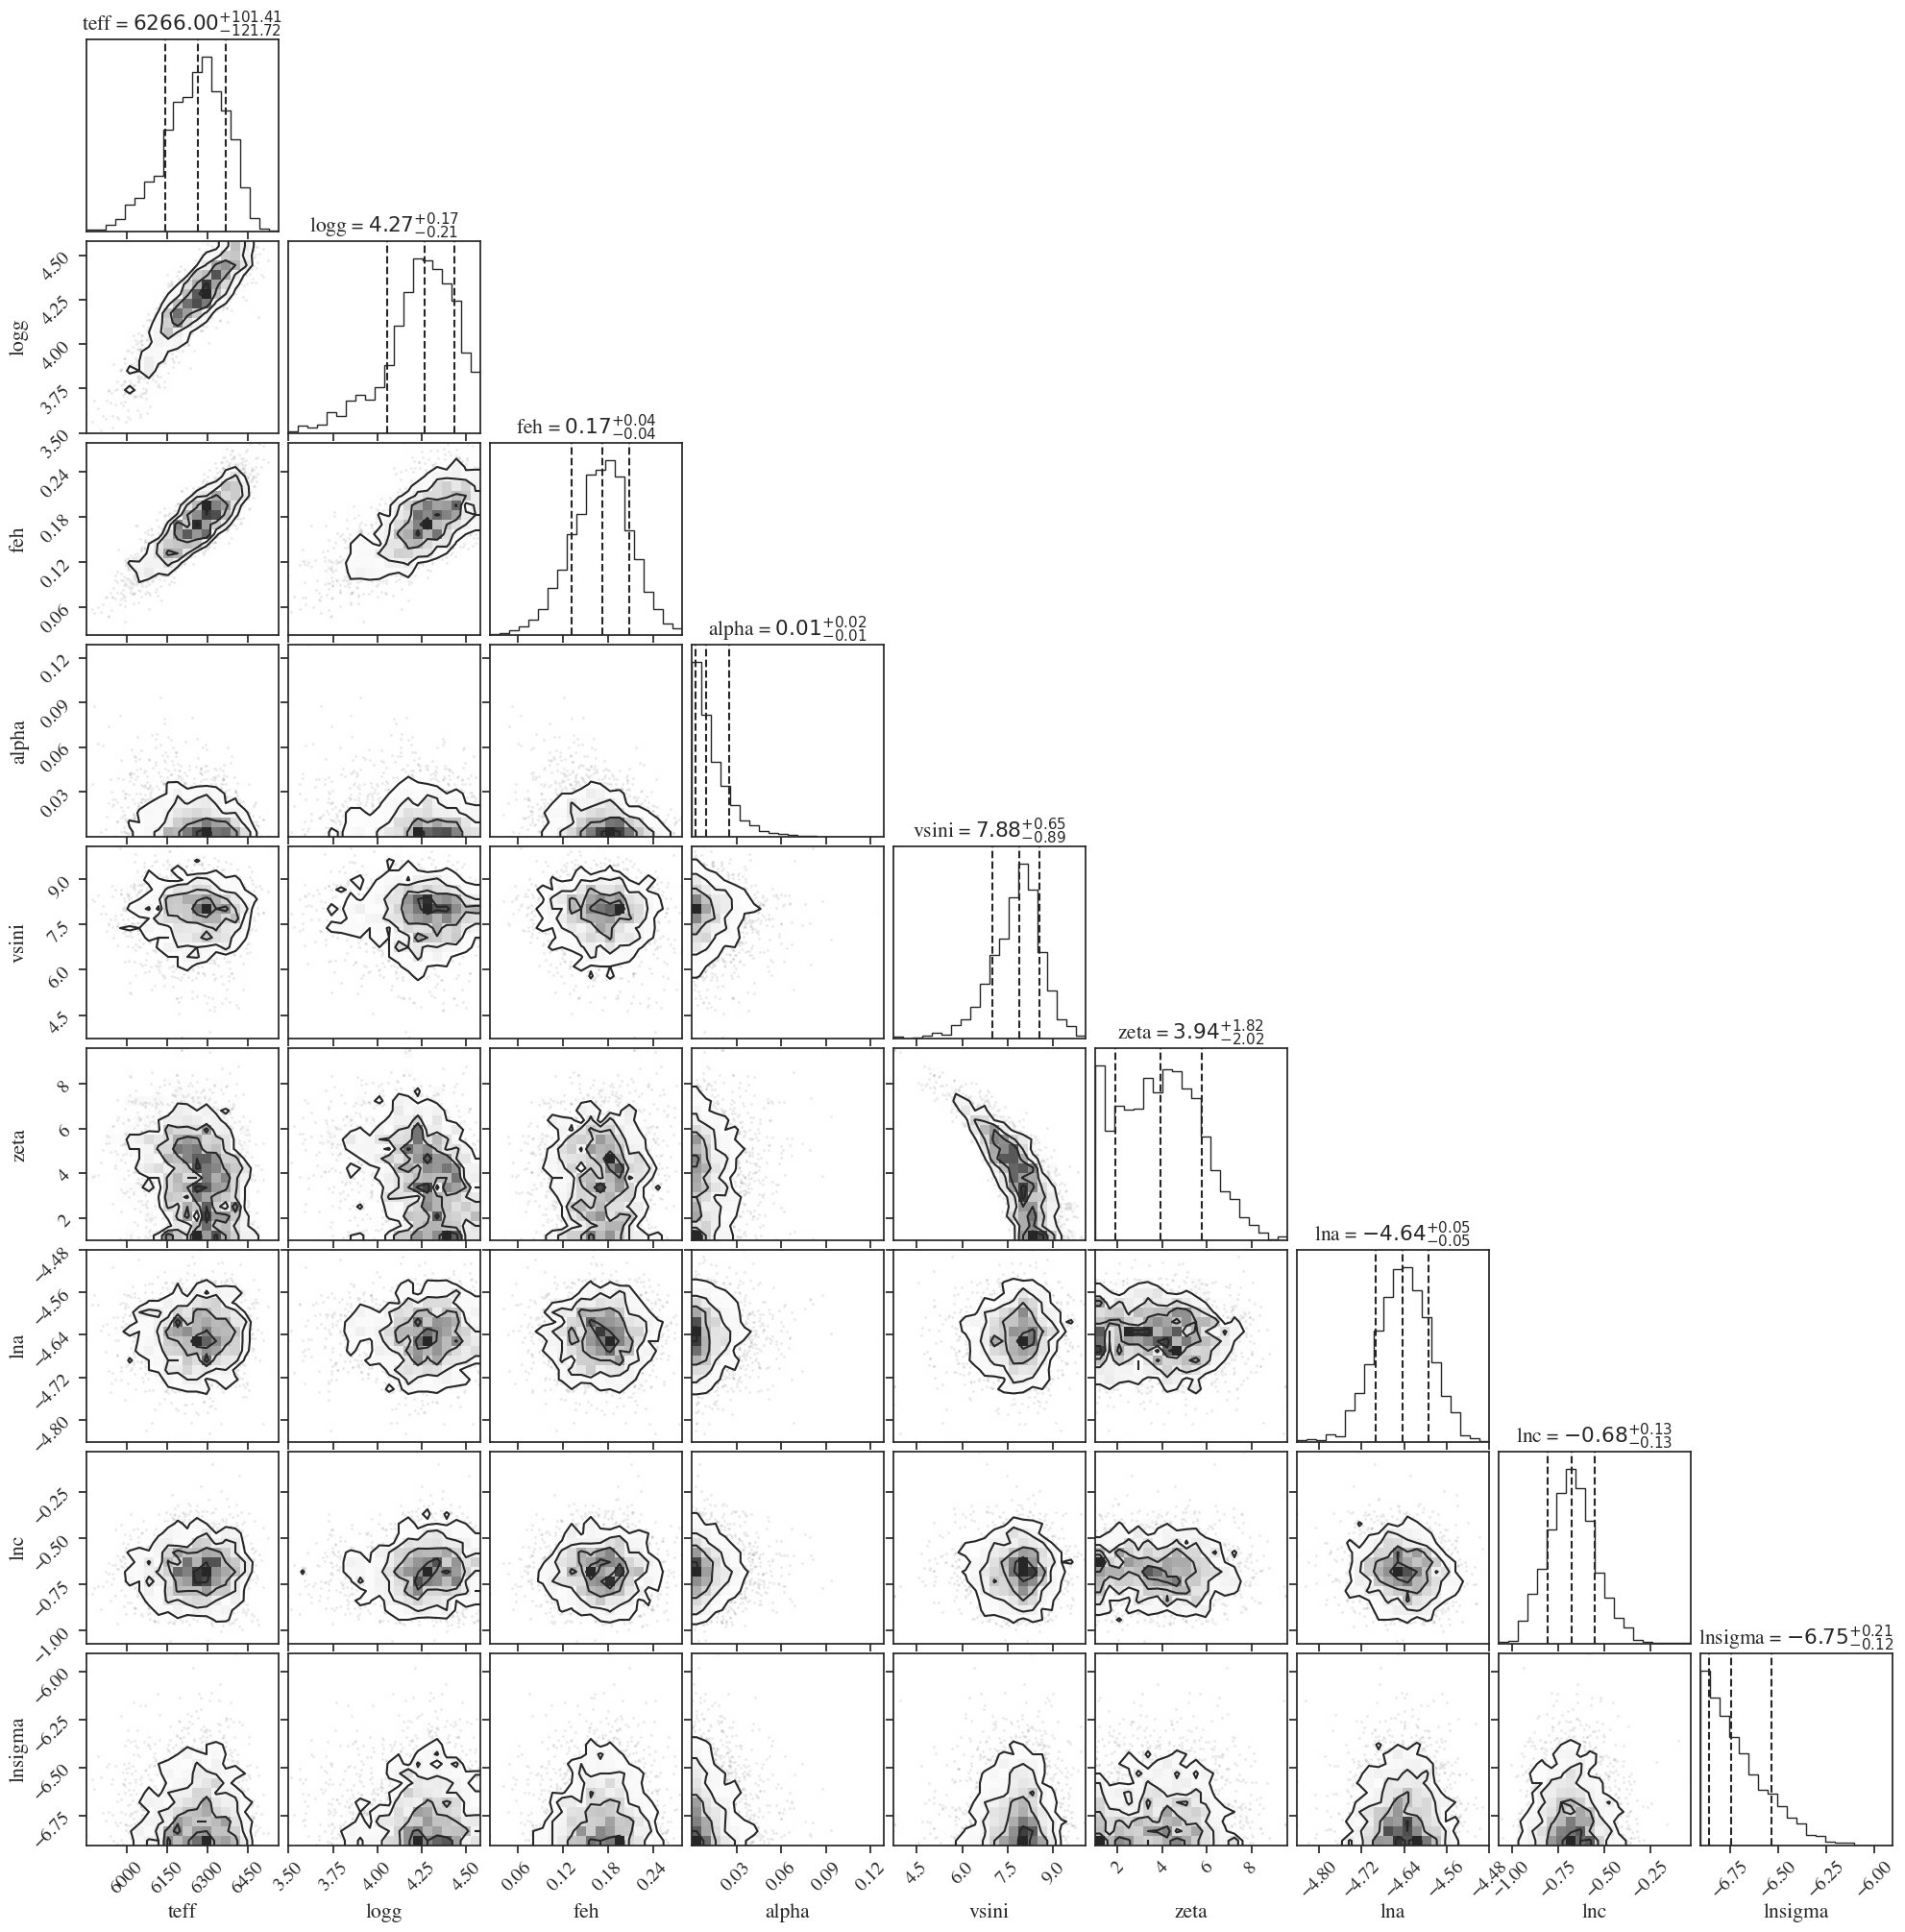

In [21]:
corner_vars = ["teff", "logg", "feh", "alpha", "vsini", "vmacro"]
log_vars = ["jitter"]
if USE_GP:
    corner_vars.extend(["gp_amplitude", "gp_scale"])
    log_vars.extend(["gp_amplitude", "gp_scale"])
corner_vars.append("jitter")

mcmc_figures = sf.plot_mcmc_diagnostics(
    mcmc,
    corner_vars=corner_vars,
    log_vars=log_vars,
    labels={
        "vmacro": "zeta", "gp_amplitude": "lna",
        "gp_scale": "lnc", "jitter": "lnsigma",
    },
)
for name, fig in mcmc_figures.items():
    fig.savefig(result_dir / f"{name}.pdf", bbox_inches="tight")
plt.show()


## 11. Save and reload the fit results

`save_fit_result` writes a result bundle to the `result_dir` chosen at the start:

| File | Contents |
| --- | --- |
| `arrays.npz` | Point estimate, observed arrays, fixed mask, and fit mask |
| `posterior.nc` | Posterior samples and collected MCMC diagnostics |
| `result.json` | Model settings, grid provenance, software metadata, and file manifest |

Saving uses the existing point estimate and MCMC results without rerunning
inference or spectrum prediction. PDFs are written by the corresponding
plotting cells. Keep the fitter's data and mask consistent with the sampling
run until the bundle has been saved.

With `overwrite=False`, saving stops if managed result files already exist.
Use a new `result_dir` for another analysis, or set `overwrite=True` to replace
an existing bundle deliberately. To save only a point estimate, omit
`mcmc=mcmc`; no `posterior.nc` is written in that case.

In [ ]:
from jaxstar.specfit import save_fit_result, load_fit_result, plot_mcmc_diagnostics

_ = save_fit_result(
    result_dir, sf=sf, model=model, point=p_fit, mcmc=mcmc,
    metadata={"data_path": str(datapath), "orders": orders},
    overwrite=False,
)

### Load the saved bundle

`load_fit_result` and the standalone `plot_mcmc_diagnostics` function work
without loading a spectral grid or constructing a fitter. In a new session,
import these functions and set `result_dir` to the saved directory before
running the following cell.

`result.point` contains the point estimate. `result.samples` combines the chain
and draw axes for use in prediction, while `result.idata` preserves them for
diagnostics. The latter is an ArviZ `InferenceData` with ArviZ 0.x or a `DataTree`
with ArviZ 1.x.

The example displays diagnostics for a smaller selection of parameters directly
from the saved posterior. It does not write another set of PDFs.

In [ ]:
result = load_fit_result(result_dir)
p_saved = result.point
samples_saved = result.samples
idata_saved = result.idata
print("Posterior dimensions:", dict(idata_saved.posterior.sizes))

saved_diagnostics = plot_mcmc_diagnostics(
    result, corner_vars=["teff", "logg", "feh", "vsini"],
)
plt.show()


### Reconstruct spectra from saved samples

The bundle contains observations, masks, and descriptive model/grid metadata,
but not the grid arrays or an executable model. In this session, reuse
`sf.specmodel` and `model`, restore the saved fit mask, and predict from the
saved samples:

```python
restored_sf = SpecFit(result.observation, sf.specmodel)
restored_sf.set_fit_mask(result.fit_mask)
restored_figures = restored_sf.plot_models(
    samples=result.samples, model=model, show_gp=USE_GP, max_draws=50,
)
plt.show()
```

In a new session, first load the same grid and construct a model with the saved
settings, including the resolved prior bounds. `result.metadata` records these
settings and the grid information for reference; `load_fit_result` does not
rebuild the model automatically.